In [1]:
from datasets import load_dataset

stream = load_dataset("Project-AgML/potato_leaf_blight", split="train", streaming=True)
first = next(iter(stream))

print("Columns:", list(first.keys()))
for key, value in first.items():
    print(f"{key:12s} -> {type(value).__name__}: {str(value)[:80]}")

E:\UBC\UBC TERM 1\ENGR 501- Deep Learning (and Reinforcement Learning) for Engineers\PROJECT\potato-disease-cnn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
E:\UBC\UBC TERM 1\ENGR 501- Deep Learning (and Reinforcement Learning) for Engineers\PROJECT\potato-disease-cnn\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\kalpa\.cache\huggingface\hub\datasets--Project-AgML--potato_leaf_blight. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/hugg

Columns: ['image', 'label']
image        -> Image: <PIL.Image.Image image mode=RGB size=1000x762 at 0x29B57A2F7A0>
label        -> int: 1


In [2]:
#Cell 2: Find the label names and check the ordering
from collections import Counter

names = stream.features["label"].names
print("Hugging Face label names:", names)

# Look at the labels of the first 300 images to see how classes are ordered
peek = Counter(example["label"] for example, _ in zip(stream, range(300)))
print("First 300 images by class:", {names[k]: v for k, v in peek.items()})

Hugging Face label names: ['earlyblt', 'healthy', 'lateblt']
First 300 images by class: {'healthy': 300}


In [3]:
#Cell 3: Sample 100 field images per class and save them
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.config import CLASSES

FIELD_DIR = ROOT / "data" / "field"
PER_CLASS = 100
MAX_STREAMED = 4000  # safety limit so it can't run forever

# Translate Hugging Face label numbers -> our label numbers
HF_TO_OURS = {
    names.index("earlyblt"): CLASSES.index("Potato___Early_blight"),
    names.index("lateblt"): CLASSES.index("Potato___Late_blight"),
    names.index("healthy"): CLASSES.index("Potato___healthy"),
}
print("HF -> ours:", HF_TO_OURS)
print("Shards:", getattr(stream, "num_shards", getattr(stream, "n_shards", "unknown")))

for c in CLASSES:
    (FIELD_DIR / c).mkdir(parents=True, exist_ok=True)

counts = {c: 0 for c in CLASSES}
shuffled = stream.shuffle(seed=42, buffer_size=500)

for i, ex in enumerate(shuffled):
    cls = CLASSES[HF_TO_OURS[ex["label"]]]
    if counts[cls] < PER_CLASS:
        ex["image"].convert("RGB").save(FIELD_DIR / cls / f"field_{counts[cls]:03d}.jpg", quality=95)
        counts[cls] += 1
    if all(v >= PER_CLASS for v in counts.values()) or i + 1 >= MAX_STREAMED:
        break
    if (i + 1) % 200 == 0:
        print(f"streamed {i + 1}: {counts}")

print(f"\nDone. Streamed {i + 1} images. Saved: {counts}")

HF -> ours: {0: 0, 2: 1, 1: 2}
Shards: 17
streamed 200: {'Potato___Early_blight': 85, 'Potato___Late_blight': 31, 'Potato___healthy': 84}
streamed 400: {'Potato___Early_blight': 100, 'Potato___Late_blight': 75, 'Potato___healthy': 100}

Done. Streamed 525 images. Saved: {'Potato___Early_blight': 100, 'Potato___Late_blight': 100, 'Potato___healthy': 100}


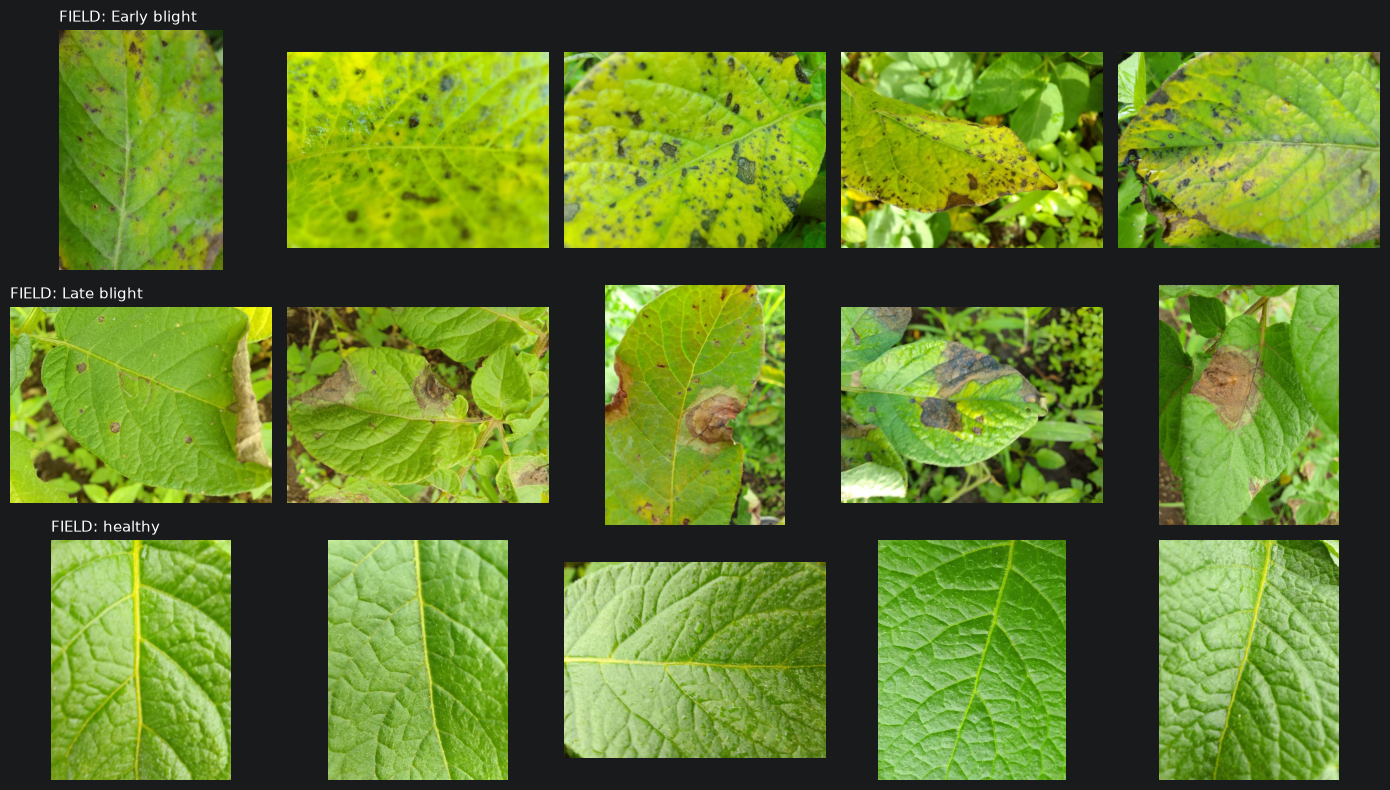

In [4]:
#Cell 4: Look at the field images first
import matplotlib.pyplot as plt
from PIL import Image

short = [c.replace("Potato___", "").replace("_", " ") for c in CLASSES]

fig, axes = plt.subplots(len(CLASSES), 5, figsize=(14, 8))
for r, c in enumerate(CLASSES):
    files = sorted((FIELD_DIR / c).glob("*.jpg"))[:5]
    for k, path in enumerate(files):
        axes[r, k].imshow(Image.open(path))
        axes[r, k].axis("off")
    axes[r, 0].set_title(f"FIELD: {short[r]}", loc="left", fontsize=11)

plt.tight_layout()
plt.savefig(ROOT / "results" / "figures" / "field_sample_images.png", dpi=200)
plt.show()

In [5]:
#Cell 5: Test all four models on the field images
import json

import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import recall_score
from torch.utils.data import DataLoader

from src.config import MODELS_DIR, RESULTS_DIR
from src.dataset import PotatoDataset, get_transforms
from src.models import SmallCNN, build_mobilenet_v3, build_resnet18
from src.train import evaluate

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
HEALTHY = CLASSES.index("Potato___healthy")

# 1. List the field images in a CSV, same format as train/val/test
rows = [{"path": p.relative_to(ROOT).as_posix(), "class_name": c, "label": i}
        for i, c in enumerate(CLASSES) for p in sorted((FIELD_DIR / c).glob("*.jpg"))]
field_csv = ROOT / "data" / "splits" / "field.csv"
pd.DataFrame(rows).to_csv(field_csv, index=False)

field_loader = DataLoader(PotatoDataset(field_csv, get_transforms(augment=False)),
                          batch_size=32, shuffle=False)
print("Field images:", len(field_loader.dataset))

# 2. The four trained models: (how to rebuild it, saved weights, lab test acc, lab macro F1)
MODELS = {
    "SmallCNN (scratch)":       (lambda: SmallCNN(num_classes=3),                         "small_cnn.pth",           0.985, 0.977),
    "MobileNetV3 (frozen)":     (lambda: build_mobilenet_v3(3),                           "mobilenet_v3_frozen.pth", 0.981, 0.968),
    "ResNet18 (frozen)":        (lambda: build_resnet18(3),                               "resnet18_frozen.pth",     0.969, 0.935),
    "MobileNetV3 (fine-tuned)": (lambda: build_mobilenet_v3(3, freeze_backbone=False),    "mnv3_finetune_all.pth",   0.997, 0.991),
}

# 3. Evaluate each one on the field images (no training)
criterion = nn.CrossEntropyLoss()
summary, field_preds = [], {}
for name, (builder, weights, lab_acc, lab_f1) in MODELS.items():
    model = builder()
    model.load_state_dict(torch.load(MODELS_DIR / weights, map_location=device))
    model.to(device).eval()
    _, acc, f1, preds, labels = evaluate(model, field_loader, criterion, device)
    field_preds[name] = {"preds": preds, "labels": labels}
    summary.append({
        "model": name, "lab_acc": lab_acc, "field_acc": acc,
        "lab_macro_f1": lab_f1, "field_macro_f1": f1,
        "field_healthy_recall": recall_score(labels, preds, average=None, labels=[0, 1, 2])[HEALTHY],
    })
    print(f"{name:26s} lab acc {lab_acc:.3f} -> field acc {acc:.3f}")

table = pd.DataFrame(summary).round(3)
table["acc_drop"] = (table["lab_acc"] - table["field_acc"]).round(3)
table.to_csv(RESULTS_DIR / "field_test_summary.csv", index=False)
with open(RESULTS_DIR / "field_test_predictions.json", "w") as f:
    json.dump(field_preds, f)
table

Field images: 300
SmallCNN (scratch)         lab acc 0.985 -> field acc 0.380
MobileNetV3 (frozen)       lab acc 0.981 -> field acc 0.793
ResNet18 (frozen)          lab acc 0.969 -> field acc 0.550
MobileNetV3 (fine-tuned)   lab acc 0.997 -> field acc 0.833


,model,lab_acc,field_acc,lab_macro_f1,field_macro_f1,field_healthy_recall,acc_drop
0,SmallCNN (scratch),0.985,0.380,0.977,0.257,0.12,0.605
1,MobileNetV3 (frozen),0.981,0.793,0.968,0.793,0.67,0.188
2,ResNet18 (frozen),0.969,0.550,0.935,0.460,0.01,0.419
3,MobileNetV3 (fine-tuned),0.997,0.833,0.991,0.834,0.73,0.164


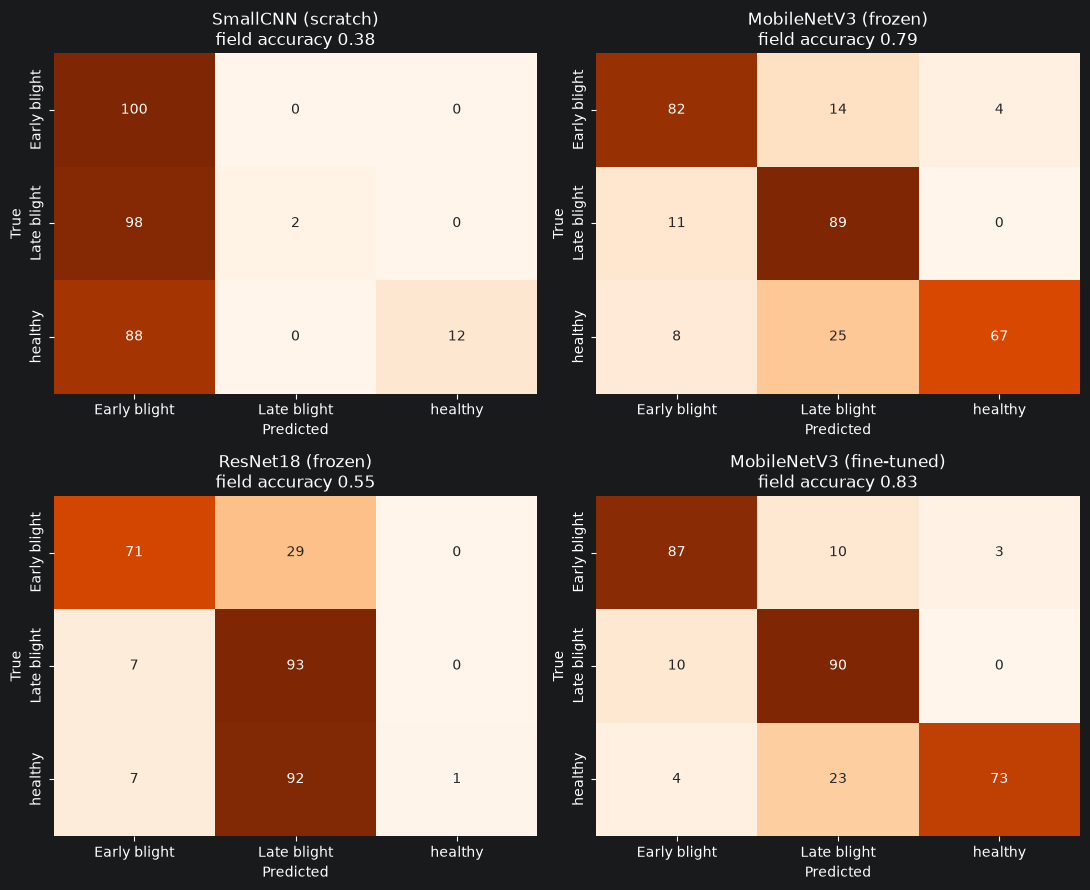

In [6]:
#Cell 6: Field confusion matrices
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, (name, r) in zip(axes.flat, field_preds.items()):
    cm = confusion_matrix(r["labels"], r["preds"], labels=range(len(CLASSES)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False,
                xticklabels=short, yticklabels=short, ax=ax)
    acc = np.trace(cm) / cm.sum()
    ax.set_title(f"{name}\nfield accuracy {acc:.2f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.savefig(ROOT / "results" / "figures" / "field_confusion_matrices.png", dpi=200)
plt.show()

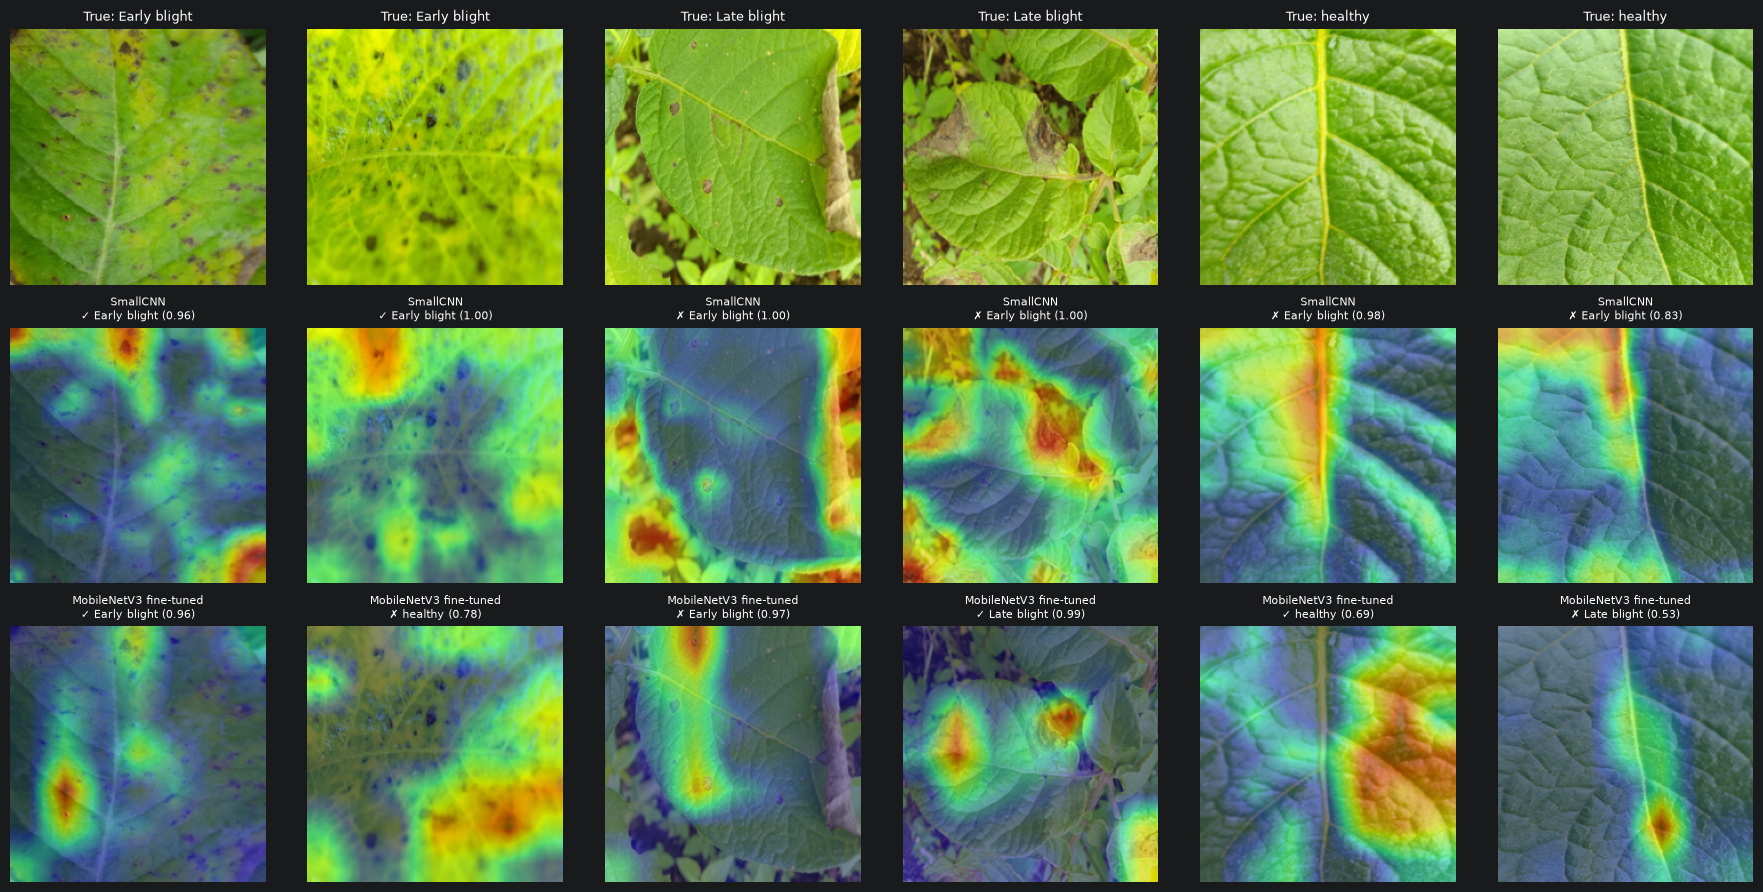

In [10]:
# Cell 7, Grad-CAM on field images (SmallCNN vs fine-tuned)import torch.nn.functional as F
import torch.nn.functional as F
from src.gradcam import GradCAM

# Rebuild both models (weights already trained)
small = SmallCNN(num_classes=3)
small.load_state_dict(torch.load(MODELS_DIR / "small_cnn.pth", map_location=device))
small.to(device).eval()
best = build_mobilenet_v3(3, freeze_backbone=False)
best.load_state_dict(torch.load(MODELS_DIR / "mnv3_finetune_all.pth", map_location=device))
best.to(device).eval()

cams = {"SmallCNN": GradCAM(small, small.features[-1]),
        "MobileNetV3 fine-tuned": GradCAM(best, best.features[-1])}

# Two field images per class
field_df = pd.read_csv(field_csv)
picks = [field_df[field_df["label"] == c].index[k] for c in range(len(CLASSES)) for k in (0, 1)]

transform = get_transforms(augment=False)
fig, axes = plt.subplots(3, len(picks), figsize=(3 * len(picks), 9))

for col, idx in enumerate(picks):
    row = field_df.iloc[idx]
    img = Image.open(ROOT / row["path"]).convert("RGB")
    x = transform(img).unsqueeze(0).to(device)
    shown = np.array(img.resize((224, 224))) / 255.0

    axes[0, col].imshow(shown)
    axes[0, col].set_title(f"True: {short[row['label']]}", fontsize=9)
    for r, (name, cam_fn) in enumerate(cams.items(), start=1):
        cam, pred, conf = cam_fn(x)
        cam_up = F.interpolate(cam[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        axes[r, col].imshow(shown)
        axes[r, col].imshow(cam_up.numpy(), cmap="jet", alpha=0.45)
        ok = "✓" if pred == row["label"] else "✗"
        axes[r, col].set_title(f"{name}\n{ok} {short[pred]} ({conf:.2f})", fontsize=8)
    for ax in axes[:, col]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(ROOT / "results" / "figures" / "field_gradcam_comparison.png", dpi=200)
plt.show()
